# AlloViewer: inference on a simulated microscopy image

This example reproduces **cell instance segmentation** using AlloViewer's released UNet checkpoint (`best_small.pth`). The input is generated with **AlloViewer's own image simulator**, using the standard `train_scene()` settings and the built-in `microscope` camera style.

The demonstration uses **one 512 × 512 RGB image**, matching the UNet tile size. No multi-tile stitching is necessary.

1. Generate a reproducible simulated CDC well and its known cell-instance labels.
2. Save the simulated image as PNG and load it using the production image loader.
3. Load the released UNet checkpoint and predict instance masks.
4. Show the input, simulation labels, predicted labels, and overlay.

**Scope:** The UNet performs **cell segmentation**, not downstream cell classification or cytotoxicity scoring. The simulated image is an API example rather than a test of diagnostic or segmentation accuracy. Requires an installed `alloviewer` package with its simulation modules and the released checkpoint.

In [1]:
from pathlib import Path
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

import alloviewer
from alloviewer.image_analysis import load_images
from alloviewer.image_analysis.config import INSTANCE_CONFIG, UNET_CONFIG
from alloviewer.image_analysis.segmenter import SegmenterUNetInference
from alloviewer.dev.segmentation.image_simulation import (
    simulate_image,
    train_scene,
    train_camera,
    CameraStyleConfig,
    STYLE_PARAMS_REGISTRY,
    apply_camera_style,
)

# Change this path if your downloaded checkpoint is stored elsewhere.
checkpoint_candidates = [
    Path('/alloviewer/models/best_small.pth'),
    Path('best_small.pth'),
    Path('alloviewer/models/best_small.pth'),
    Path(alloviewer.__file__).resolve().parent / 'models' / 'best_small.pth',
]
WEIGHTS_PATH = next((p.resolve() for p in checkpoint_candidates if p.is_file()), None)
if WEIGHTS_PATH is None:
    raise FileNotFoundError(
        'best_small.pth was not found. Place it next to this notebook or '
        'update checkpoint_candidates to its downloaded location.'
    )
print(f'Checkpoint: {WEIGHTS_PATH}')

Checkpoint: C:\Users\tarik\Python\LCTeller\alloviewer\models\best_small.pth


## 1. Generate a genuine AlloViewer simulation

`train_scene()` is the standard scene preset. A `train_camera()` configuration is set to a fixed **512 × 512** image so the image fits a single inference tile. The scene's sampled cell number is set to **180** to avoid overcrowding the smaller well; the other scene settings are left as sampled from the preset.

We then apply the built-in `microscope` camera style. The optional real-device histogram cache is not used, so this demonstrates the built-in image effects without histogram matching to acquired data.

To analyze an acquired image instead, set `IMAGE_PATH` to an existing `.png` or `.tif` file. In that case the simulation step is skipped.

In [2]:
IMAGE_PATH = None  # e.g., Path('data/example_cdc.tif')
SEED = 42
IMAGE_SIZE = 512
GROUND_TRUTH = None

if IMAGE_PATH is None:
    rng = np.random.default_rng(SEED)

    # Use the package's ordinary simulation settings and fix only the size/density.
    camera = train_camera()
    camera.H = IMAGE_SIZE
    camera.W = IMAGE_SIZE
    kwargs = train_scene().sample_kwargs(rng, camera=camera)
    kwargs.update(n_cells=180, seed=SEED, return_targets=True)

    simulated_image, metadata, targets = simulate_image(**kwargs)
    assert simulated_image.shape == (IMAGE_SIZE, IMAGE_SIZE, 3)
    GROUND_TRUTH = targets['instance_labels']

    microscope_style = CameraStyleConfig(styles=('microscope',), probs=None)
    simulated_image = apply_camera_style(
        simulated_image,
        rng,
        microscope_style,
        STYLE_PARAMS_REGISTRY,
        cell_mask=targets['cell_mask'],
    )

    # Save uint8 RGB so input passes through the same loader as acquired data.
    IMAGE_PATH = Path('alloviewer_simulated_512.png')
    Image.fromarray(np.round(np.clip(simulated_image, 0, 1) * 255).astype(np.uint8)).save(IMAGE_PATH)
else:
    IMAGE_PATH = Path(IMAGE_PATH)
    if not IMAGE_PATH.is_file():
        raise FileNotFoundError(IMAGE_PATH)

input_image = load_images(
    [IMAGE_PATH.name], str(IMAGE_PATH.parent.resolve()), scale=True
)[0]

# AlloViewer loads (C, H, W) float32 images, while plots use (H, W, C).
assert input_image.shape == (3, IMAGE_SIZE, IMAGE_SIZE), input_image.shape
print(f'Input: {IMAGE_PATH} | shape={input_image.shape} | dtype={input_image.dtype}')
if GROUND_TRUTH is not None:
    print(f'Simulated true cell instances: {len(np.unique(GROUND_TRUTH[GROUND_TRUTH > 0]))}')

Input: alloviewer_simulated_512.png | shape=(3, 512, 512) | dtype=float32
Simulated true cell instances: 180


## 2. Run the released segmentation model

Use the same `SegmenterUNetInference.from_config` entry point as the production image-analysis pipeline. The two checkpoint settings are set explicitly, so inference cannot accidentally load a different model. The input is 512 × 512, equal to `tile_size`; this creates exactly **one inference tile**.

In [3]:
config = copy.deepcopy(UNET_CONFIG)
config.setdefault('instance_cfg', INSTANCE_CONFIG.to_dict())
config['unet_mode'] = 'small'
config['model_dir'] = str(WEIGHTS_PATH.parent)
config['model_file'] = WEIGHTS_PATH.name
config['tile_size'] = IMAGE_SIZE

segmenter = SegmenterUNetInference.from_config(config)
assert segmenter.tile_size == IMAGE_SIZE

with torch.inference_mode():
    segmentation = segmenter(input_image)

instance_labels = np.asarray(segmentation['instance_labels'])
assert instance_labels.shape == (IMAGE_SIZE, IMAGE_SIZE), instance_labels.shape
n_cells = int(np.unique(instance_labels[instance_labels > 0]).size)

print(f'Model device: {segmenter.device}')
print(f'Predicted cell instances: {n_cells}')

C:\Users\tarik\Python\LCTeller\alloviewer\example\../../../LCTeller\alloviewer\image_analysis\segmenter.py:305: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.l

Model device: cpu
Predicted cell instances: 176


## 3. Inspect the result

Predicted `instance_labels` is an integer array of shape `(512, 512)`; `0` marks the background and positive integers mark individual cells. The simulated ground truth is shown only for the generated example. Counts are descriptive, not an accuracy benchmark.

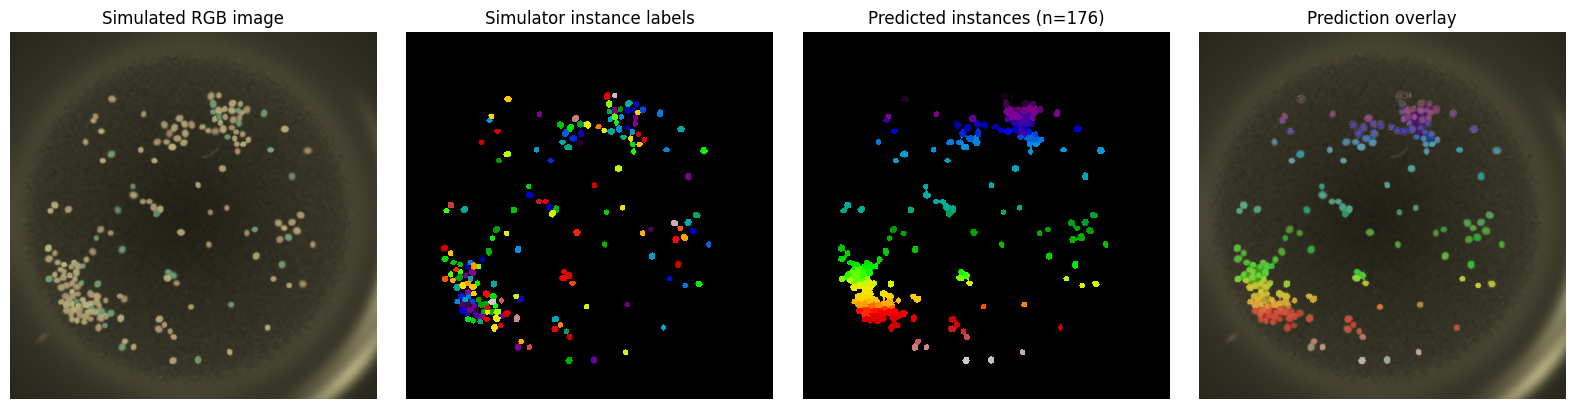

In [4]:
display_image = np.clip(np.moveaxis(input_image, 0, -1), 0, 1)
predicted_overlay = np.ma.masked_where(instance_labels == 0, instance_labels)

if GROUND_TRUTH is None:
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(display_image)
    axes[0].set_title('Input RGB image')
    axes[1].imshow(instance_labels, cmap='nipy_spectral', interpolation='nearest')
    axes[1].set_title(f'Predicted instances (n={n_cells})')
    axes[2].imshow(display_image)
    axes[2].imshow(predicted_overlay, cmap='nipy_spectral', alpha=0.5, interpolation='nearest')
    axes[2].set_title('Prediction overlay')
else:
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(display_image)
    axes[0].set_title('Simulated RGB image')
    axes[1].imshow(GROUND_TRUTH, cmap='nipy_spectral', interpolation='nearest')
    axes[1].set_title('Simulator instance labels')
    axes[2].imshow(instance_labels, cmap='nipy_spectral', interpolation='nearest')
    axes[2].set_title(f'Predicted instances (n={n_cells})')
    axes[3].imshow(display_image)
    axes[3].imshow(predicted_overlay, cmap='nipy_spectral', alpha=0.5, interpolation='nearest')
    axes[3].set_title('Prediction overlay')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# Optional: save labels for downstream work.
# np.save('alloviewer_predicted_labels.npy', instance_labels)